In [21]:
# --- IMPORTS & DATA LOADING ---

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Visual configurations
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("Libraries imported successfully!")


Libraries imported successfully!


In [22]:
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

df_final = pd.read_parquet("../data/processed/pld_se_co_monthly.parquet")
display(df_final.head())
print(f"Loaded {len(df_final)} months")



,pld_se_co,load_seco_mwmed,ear_seco_mwmes,ena_seco_mwmed,thermal_gen_seco_mwmed
date,,,,,
2017-01-01,121.44,39881.955585,69836.612903,43990.903226,4221.813172
2017-02-01,128.43,40979.009545,80383.464286,49413.428571,4145.487351
2017-03-01,216.24,40491.735269,83858.096774,45626.032258,5496.185484
2017-04-01,371.47,37739.542232,84446.433333,39045.966667,6608.565278
2017-05-01,411.49,36876.019168,85763.161290,38930.387097,6202.169355


Loaded 105 months


## Q1: Is the PLD in SE/CO different between dry and wet hydrological periods?

In [23]:
# 1. Define the hydrological period of each month (dry: May-Nov, wet: Dec-Apr)

def get_period(month):
    """
    Return the hydrological period of a given month number.
    """
    
    if month >= 5 and month <= 11:
        return "dry"
    else:
        return "wet"

df_q1 = df_final.copy()
df_q1["period"] = df_q1.index.month.map(get_period)

# 2. Descriptive statistics by period
print(df_q1.groupby("period")["pld_se_co"].describe())

        count        mean         std    min      25%      50%      75%  \
period                                                                    
dry      61.0  232.582295  173.254636  55.70  78.5200  210.020  325.460   
wet      44.0  144.157955   98.336568  39.68  64.3275  109.365  205.695   

           max  
period          
dry     583.88  
wet     443.66  


* The dry period has a higher and more volatile PLD: mean of R$ 232.6/MWh vs R$ 144.2/MWh in the wet period, and a median of R$ 210.0 vs R$ 109.4 (61 dry months vs 44 wet months).
* The dry period spread is much larger (std of 173.3 vs 98.3), and its mean is above its median, a sign of a right-skewed distribution driven by price spikes.
* The lower quartiles are similar (R$ 78.5 vs R$ 64.3), consistent with the regulatory price floor limiting how low the PLD can go in both periods.

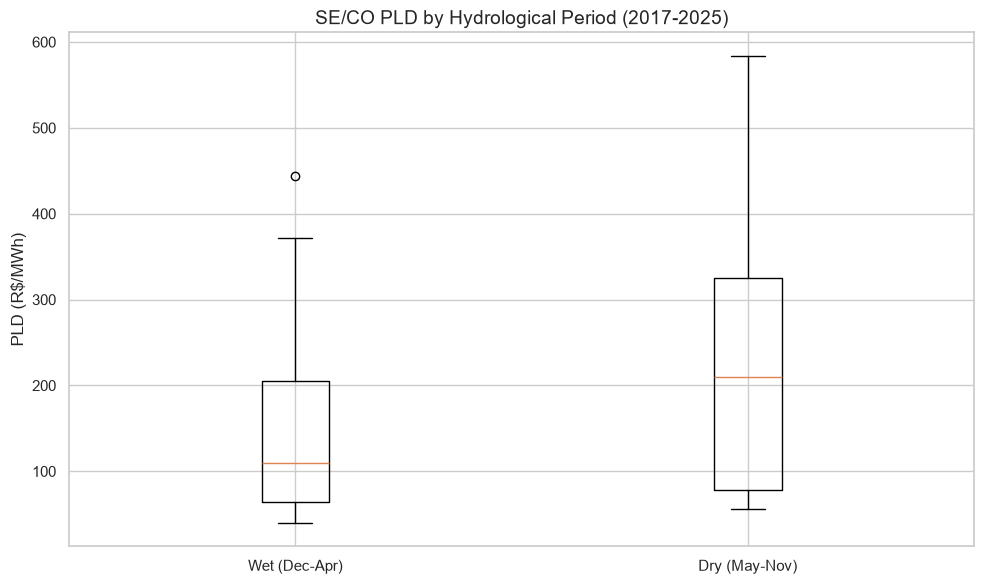

In [24]:
# 3. Boxplot
dry = df_q1.loc[df_q1["period"] == "dry", "pld_se_co"]
wet = df_q1.loc[df_q1["period"] == "wet", "pld_se_co"]

plt.figure(figsize=(10, 6))
plt.boxplot([wet, dry], tick_labels=["Wet (Dec-Apr)", "Dry (May-Nov)"])
plt.ylabel("PLD (R$/MWh)")
plt.title("SE/CO PLD by Hydrological Period (2017-2025)", fontsize=14)
plt.tight_layout()
plt.savefig("../outputs/boxplot_pld_dry_vs_wet.png", dpi=300)
plt.show()


* The dry period median (~R$ 210/MWh) is almost equal to the 75th percentile of the wet period (~R$ 206/MWh): a typical dry month is as expensive as a high wet month.
* The dry period has a much wider box and upper whisker (up to R$ 584/MWh), while the wet period is more concentrated, with a single outlier (~R$ 444/MWh).
* Both periods share a similar lower bound, so the difference is concentrated in the upper part of the distribution (price spikes), not in the cheapest months.

In [25]:
# 4. Hypothesis test (Mann-Whitney) + difference and bootstrap confidence interval

def compare_periods(dry_values, wet_values):
    """Run Mann-Whitney and print the difference in means with a 95% bootstrap CI."""
    stat, p_value = stats.mannwhitneyu(dry_values, wet_values, alternative="two-sided")

    mean_diff = dry_values.mean() - wet_values.mean()
    pct_diff = mean_diff / wet_values.mean() * 100

    # Bootstrap: resample each group with replacement 5000 times
    
    rng = np.random.default_rng(42)
    diffs = []
    for i in range(5000):
        sample_dry = rng.choice(dry_values, size=len(dry_values), replace=True)
        sample_wet = rng.choice(wet_values, size=len(wet_values), replace=True)
        diffs.append(sample_dry.mean() - sample_wet.mean())
    ci_low, ci_high = np.percentile(diffs, [2.5, 97.5])

    print(f"Mann-Whitney p-value: {p_value:.4f}")
    print(f"Mean PLD dry: {dry_values.mean():.1f} | wet: {wet_values.mean():.1f} (R$/MWh)")
    print(f"Difference (dry - wet): {mean_diff:.1f} R$/MWh ({pct_diff:.1f}%)")
    print(f"95% bootstrap CI for the difference: [{ci_low:.1f}, {ci_high:.1f}]")

print("=== Full period (2017-2025) ===")
compare_periods(dry, wet)

# 5. Robustness: exclude 2022-2024 (PLD at the regulatory floor)
df_robust = df_q1[(df_q1.index.year < 2022) | (df_q1.index.year > 2024)]
dry_r = df_robust.loc[df_robust["period"] == "dry", "pld_se_co"]
wet_r = df_robust.loc[df_robust["period"] == "wet", "pld_se_co"]

print("\n=== Excluding 2022-2024 ===")
compare_periods(dry_r, wet_r)

=== Full period (2017-2025) ===
Mann-Whitney p-value: 0.0072
Mean PLD dry: 232.6 | wet: 144.2 (R$/MWh)
Difference (dry - wet): 88.4 R$/MWh (61.3%)
95% bootstrap CI for the difference: [35.7, 141.0]

=== Excluding 2022-2024 ===
Mann-Whitney p-value: 0.0031
Mean PLD dry: 300.6 | wet: 186.1 (R$/MWh)
Difference (dry - wet): 114.5 R$/MWh (61.5%)
95% bootstrap CI for the difference: [52.2, 177.4]


* The difference is statistically significant: the dry period PLD is R$ 88.4/MWh (61.3%) higher than the wet period (Mann-Whitney p = 0.007), and the 95% bootstrap CI [35.7, 141.0] does not include zero.
* Robustness: excluding 2022-2024 (PLD at the regulatory floor) the result holds and the gap widens to R$ 114.5/MWh (CI [52.2, 177.4], p = 0.003). The relative difference is nearly the same (61.5%), so the floor years dilute the absolute gap but do not create it.
* Caveat: consecutive months are autocorrelated, so the p-values are likely optimistic and the confidence intervals are wide. The 2021 water crisis falls in the dry period and may inflate part of the gap.

## Q2: How much of the PLD variation is explained by EAR and ENA?

In [29]:
# --- Q2: PREPARATION ---
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1. Rescale EAR, ENA, load and thermal to thousands of MW for readable coefficients
df_q2 = df_final.copy()
df_q2["ear_k"] = df_q2["ear_seco_mwmes"] / 1000
df_q2["ena_k"] = df_q2["ena_seco_mwmed"] / 1000
df_q2["load_k"] = df_q2["load_seco_mwmed"] / 1000
df_q2["thermal_k"] = df_q2["thermal_gen_seco_mwmed"] / 1000

features_a = ["ear_k", "ena_k"]
features_b = ["ear_k", "ena_k", "thermal_k", "load_k"]

# 2. Helper: fit OLS with HAC (Newey-West) standard errors
def fit_ols(data, features):
    """
    Fit PLD ~ features with autocorrelation-robust standard errors.
    """
    
    X = sm.add_constant(data[features])
    y = data["pld_se_co"]
    model = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
    return model

# 3. Helper: print VIF for each feature
def print_vif(data, features):
    """
    Print the variance inflation factor of each feature.
    """
    
    X = sm.add_constant(data[features])
    for i, col in enumerate(X.columns):
        if col != "const":
            print(f"VIF {col}: {variance_inflation_factor(X.values, i):.2f}")

In [30]:
# --- Q2: MODELS ON THE FULL PERIOD ---

model_a = fit_ols(df_q2, features_a)
model_b = fit_ols(df_q2, features_b)

print("=== Model A: EAR + ENA ===")
print(model_a.summary().tables[1])
print(f"R2: {model_a.rsquared:.3f} | Adjusted R2: {model_a.rsquared_adj:.3f}\n")

print("=== Model B: EAR + ENA + thermal + load ===")
print(model_b.summary().tables[1])
print(f"R2: {model_b.rsquared:.3f} | Adjusted R2: {model_b.rsquared_adj:.3f}\n")

print("=== Multicollinearity (Model B) ===")
print_vif(df_q2, features_b)

=== Model A: EAR + ENA ===
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        492.2849     58.911      8.356      0.000     376.822     607.748
ear_k         -2.0789      0.384     -5.413      0.000      -2.832      -1.326
ena_k         -2.9299      0.817     -3.587      0.000      -4.531      -1.329
R2: 0.427 | Adjusted R2: 0.416

=== Model B: EAR + ENA + thermal + load ===
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        125.2716    159.404      0.786      0.432    -187.154     437.697
ear_k         -0.5588      0.322     -1.735      0.083      -1.190       0.072
ena_k         -2.2390      0.802     -2.792      0.005      -3.810      -0.667
thermal_k     48.1903     13.115      3.674      0.000      22.485      73.896
load_k        -0.4668      3

#### Explanatory Power (Adjusted $R^2$)
* **Full Period (105 months):** Adding thermal dispatch and load to the baseline model significantly increases its explanatory power. The Adjusted $R^2$ jumps from **0.416** (Model A) to **0.554** (Model B). This confirms that spot prices (PLD) are heavily influenced by the system operator's short-term decisions, rather than hydrological conditions alone.
* **Robustness Sample (Excluding 2022-2024):** When we exclude the recent years where the PLD was frequently pinned at the regulatory floor, the performance of both models drops (Model B falls to an Adjusted $R^2$ of **0.415**)[cite: 16]. This reveals that linear regressions rely on periods of high volatility (spikes and deep valleys) to establish a strong trend. Without these extreme variations, predicting the baseline price noise becomes harder for a simple linear estimator

,Model,Sample,N,Adj. R2
0,A: EAR + ENA,Full period,105,0.416
1,B: + thermal + load,Full period,105,0.554
2,A: EAR + ENA,Excl. 2022-2024,69,0.312
3,B: + thermal + load,Excl. 2022-2024,69,0.415


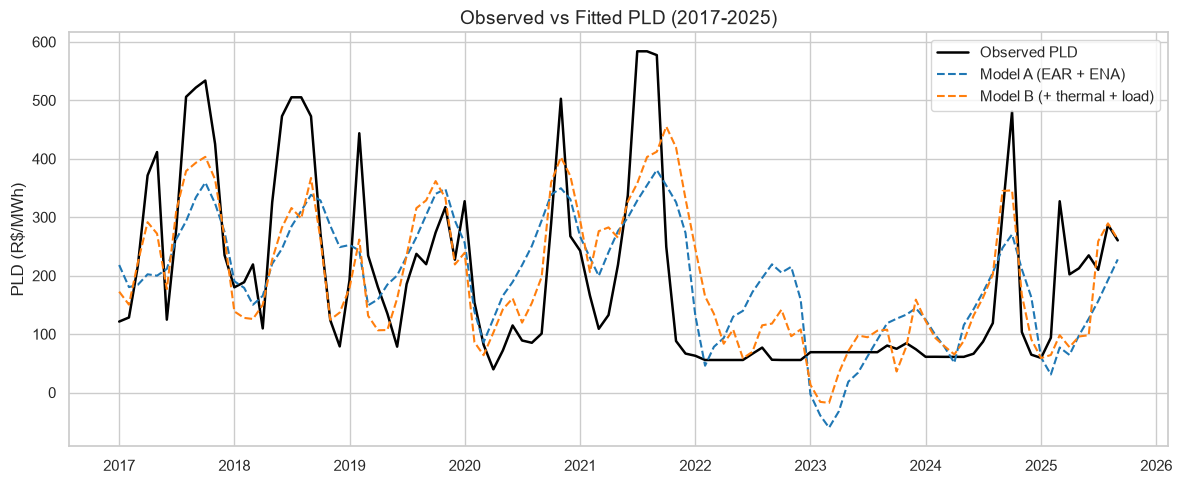

In [31]:
# --- Q2: ROBUSTNESS, SUMMARY TABLE AND OBSERVED VS FITTED ---

# 1. Robustness: exclude 2022-2024 (PLD at the regulatory floor)
df_q2_robust = df_q2[(df_q2.index.year < 2022) | (df_q2.index.year > 2024)]
model_a_r = fit_ols(df_q2_robust, features_a)
model_b_r = fit_ols(df_q2_robust, features_b)

# 2. Summary table
summary = pd.DataFrame({
    "Model": ["A: EAR + ENA", "B: + thermal + load"] * 2,
    "Sample": ["Full period"] * 2 + ["Excl. 2022-2024"] * 2,
    "N": [len(df_q2)] * 2 + [len(df_q2_robust)] * 2,
    "Adj. R2": [model_a.rsquared_adj, model_b.rsquared_adj,
                model_a_r.rsquared_adj, model_b_r.rsquared_adj],
})
display(summary.round(3))

# 3. Observed vs fitted (full period)
plt.figure(figsize=(12, 5))
plt.plot(df_q2.index, df_q2["pld_se_co"], color="black", linewidth=1.8, label="Observed PLD")
plt.plot(df_q2.index, model_a.fittedvalues, color="tab:blue", linestyle="--", label="Model A (EAR + ENA)")
plt.plot(df_q2.index, model_b.fittedvalues, color="tab:orange", linestyle="--", label="Model B (+ thermal + load)")
plt.ylabel("PLD (R$/MWh)")
plt.title("Observed vs Fitted PLD (2017-2025)", fontsize=14)
plt.legend()
plt.tight_layout()
plt.savefig("../outputs/pld_observed_vs_fitted.png", dpi=300)
plt.show()

#### Visual Fit (Observed vs. Fitted PLD)
* **Tracking the Trend:** The orange dashed line (Model B) follows the observed PLD (solid black line) much more accurately than the blue dashed line (Model A)[cite: 16]. 
* **Preventing Unrealistic Drops:** Notice the period around 2023: Model A predicts negative prices (which is economically impossible in this regulatory framework), whereas Model B adjusts for the actual operational reality and stays much closer to the observed regulatory floor[cite: 16].
* **Limitation on Extreme Spikes:** Both models systematically underestimate the extreme price spikes (e.g., the peaks nearing 600 R$/MWh in late 2021)[cite: 16]. This is a classic limitation of Ordinary Least Squares (OLS) models, which tend to smooth out extreme scarcity pricing events in favor of minimizing the average error.